# Final Report — Anime-Style Japanese Speech Emotion Recognition

**Reporting and verification notebook only.** This notebook reads the frozen 1,969-sample canonical experiment and separately versioned analysis artifacts. It does not train, tune, split, cluster, pseudo-label, or evaluate a model.

The original `anime_ser.ipynb` remains the historical experiment notebook. Values here are loaded from the saved September 5, 2026 artifacts rather than copied from stale notebook output cells.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RUN_LOCATION = Path.cwd().resolve()
candidate_roots = [RUN_LOCATION, RUN_LOCATION.parent]
PROJECT_ROOT = next(
    (candidate for candidate in candidate_roots
     if (candidate / "output" / "anime_only_final_results.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not find the Anime_SER_More_Sample output directory from this location."
    )

OUTPUT = PROJECT_ROOT / "output"
TEXT_EXP = PROJECT_ROOT / "experiments" / "text_char_ngram"
WEIGHTED_EXP = PROJECT_ROOT / "experiments" / "neural_class_weighted"
MULTISEED_EXP = PROJECT_ROOT / "experiments" / "grouped_multiseed"
SPEAKER_ANALYSIS = PROJECT_ROOT / "speaker_analysis"
DURATION_ANALYSIS = PROJECT_ROOT / "duration_analysis"

EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "pleasant_surprise", "sad"]
COLORS = {"blue": "#356FA3", "gold": "#C49332", "ink": "#25313C", "grey": "#D9E0E6"}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": COLORS["ink"],
    "axes.labelcolor": COLORS["ink"], "text.color": COLORS["ink"],
    "axes.grid": True, "grid.color": "#E8ECEF", "grid.linewidth": 0.8,
    "font.size": 10, "figure.dpi": 120,
})
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 180)

def show_table(frame, decimals=4):
    display(frame.style.format(precision=decimals).hide(axis="index"))

print("Project root:", PROJECT_ROOT)
print("Mode: read-only reporting from saved artifacts")

Project root: D:\Telkom University Kuliah\Publikasi Paper\Speech Emotion Recognition on Anime-Style Japanese Voice Using Acoustic Features and Deep Learning\Anime_SER_More_Sample
Mode: read-only reporting from saved artifacts


## Source artifacts and input checks

In [2]:
artifact_paths = {
    "canonical_results": OUTPUT / "anime_only_final_results.csv",
    "canonical_classwise": OUTPUT / "classwise_results.csv",
    "train_manifest": OUTPUT / "train_manifest.csv",
    "validation_manifest": OUTPUT / "validation_manifest.csv",
    "test_manifest": OUTPUT / "test_manifest.csv",
    "dataset_summary": OUTPUT / "dataset_summary.csv",
    "pipeline_readiness": OUTPUT / "pipeline_readiness.csv",
    "text_char_results": TEXT_EXP / "final_results.csv",
    "weighted_neural_results": WEIGHTED_EXP / "final_results.csv",
    "weighted_comparison": WEIGHTED_EXP / "comparison_with_unweighted.csv",
    "multiseed_results": MULTISEED_EXP / "seed_results.csv",
    "multiseed_aggregate": MULTISEED_EXP / "aggregate_results.csv",
    "speaker_metadata": SPEAKER_ANALYSIS / "speaker_metadata.csv",
    "speaker_overlap": SPEAKER_ANALYSIS / "speaker_split_overlap.csv",
    "speaker_config": SPEAKER_ANALYSIS / "speaker_analysis_config.json",
    "duration_summary": DURATION_ANALYSIS / "duration_summary.csv",
    "duration_policy": DURATION_ANALYSIS / "duration_policy_counts.csv",
    "duration_distribution": DURATION_ANALYSIS / "duration_distribution.csv",
}
missing_artifacts = [str(path) for path in artifact_paths.values() if not path.is_file()]
if missing_artifacts:
    raise FileNotFoundError("Missing required report artifacts:\n" + "\n".join(missing_artifacts))

canonical_results = pd.read_csv(artifact_paths["canonical_results"])
canonical_classwise = pd.read_csv(artifact_paths["canonical_classwise"])
manifests = {
    split: pd.read_csv(artifact_paths[f"{split}_manifest"], low_memory=False)
    for split in ["train", "validation", "test"]
}
metadata = pd.concat(manifests.values(), ignore_index=True)
dataset_summary = pd.read_csv(artifact_paths["dataset_summary"])
pipeline_readiness = pd.read_csv(artifact_paths["pipeline_readiness"])
text_char_results = pd.read_csv(artifact_paths["text_char_results"])
weighted_results = pd.read_csv(artifact_paths["weighted_neural_results"])
multiseed_results = pd.read_csv(artifact_paths["multiseed_results"])
multiseed_aggregate = pd.read_csv(artifact_paths["multiseed_aggregate"])
speaker_metadata = pd.read_csv(artifact_paths["speaker_metadata"], low_memory=False)
speaker_overlap = pd.read_csv(artifact_paths["speaker_overlap"])
speaker_config = json.loads(artifact_paths["speaker_config"].read_text(encoding="utf-8"))
duration_summary = pd.read_csv(artifact_paths["duration_summary"])
duration_policy = pd.read_csv(artifact_paths["duration_policy"])
duration_distribution = pd.read_csv(artifact_paths["duration_distribution"], low_memory=False)

print(f"Loaded {len(artifact_paths)} versioned source artifacts.")

Loaded 18 versioned source artifacts.


## TL;DR

In [3]:
best = canonical_results.sort_values("macro_f1", ascending=False).iloc[0]
open_multi = multiseed_aggregate.loc[multiseed_aggregate["model"] == "openSMILE eGeMAPS + XGBoost"].iloc[0]
svm_multi = multiseed_aggregate.loc[multiseed_aggregate["model"] == "MFCC + SVM"].iloc[0]
within_duration = duration_policy.loc[
    duration_policy["duration_policy_category"] == "within_1.00_to_6.00_seconds"
].iloc[0]

display(Markdown(f'''
- The frozen study contains **{len(metadata):,} clips** across seven emotions, with an unchanged **{len(manifests['train']):,}/{len(manifests['validation']):,}/{len(manifests['test']):,}** train/validation/test split.
- The strongest canonical method is **{best['method']}**: test accuracy **{best['accuracy']:.4f}**, Macro-F1 **{best['macro_f1']:.4f}**.
- Across five source-group-disjoint partitions, openSMILE Macro-F1 is **{open_multi['mean_macro_f1']:.4f} ± {open_multi['std_macro_f1']:.4f}** and MFCC + SVM is **{svm_multi['mean_macro_f1']:.4f} ± {svm_multi['std_macro_f1']:.4f}**.
- **{int(within_duration['sample_count']):,}/{len(metadata):,} ({within_duration['percentage_of_dataset']:.3f}%)** clips are within the planned 1–6 s interval.
- The experiment is **source-media/episode group-disjoint**, not verified speaker-independent. Speaker clustering is exploratory and low reliability.
'''))


- The frozen study contains **1,969 clips** across seven emotions, with an unchanged **1,313/261/395** train/validation/test split.
- The strongest canonical method is **openSMILE eGeMAPS + XGBoost**: test accuracy **0.7494**, Macro-F1 **0.7517**.
- Across five source-group-disjoint partitions, openSMILE Macro-F1 is **0.7592 ± 0.0073** and MFCC + SVM is **0.7511 ± 0.0143**.
- **1,821/1,969 (92.483%)** clips are within the planned 1–6 s interval.
- The experiment is **source-media/episode group-disjoint**, not verified speaker-independent. Speaker clustering is exploratory and low reliability.


## Context and methods

### Key assumptions

- The frozen CSV artifacts are the source of truth; displayed outputs in the historical notebook are not used.
- Canonical results and follow-up improvement experiments are labeled separately.
- Macro-F1 is the primary metric because the seven emotion classes are imbalanced.
- The target is **perceived vocal emotion in the utterance**. Transcript content is supporting evidence; full-scene or visual emotion is outside the classifier target.
- Labels are quality-controlled pseudo-labels rather than human-verified ground truth. Any unfinished human audit must not be represented as completed.
- No result in this notebook is produced by a new fit, prediction, split, or test evaluation.

## Dataset and integrity

In [4]:
expected_split_sizes = {"train": 1313, "validation": 261, "test": 395}
split_sizes = {split: len(frame) for split, frame in manifests.items()}
source_groups = {split: set(frame["source_group"].astype(str)) for split, frame in manifests.items()}
integrity = pd.DataFrame([
    {"check": "Total selected clips", "observed": len(metadata), "expected": 1969, "status": "PASS" if len(metadata) == 1969 else "FAIL"},
    {"check": "Unique file paths", "observed": metadata["file_path"].nunique(), "expected": 1969, "status": "PASS" if metadata["file_path"].nunique() == 1969 else "FAIL"},
    {"check": "Unique SHA-256 values", "observed": metadata["sha256"].nunique(), "expected": 1969, "status": "PASS" if metadata["sha256"].nunique() == 1969 else "FAIL"},
    {"check": "Transcript coverage", "observed": f"{metadata['transcript'].fillna('').str.strip().ne('').mean():.1%}", "expected": "100.0%", "status": "PASS" if metadata['transcript'].fillna('').str.strip().ne('').all() else "FAIL"},
    {"check": "Train/validation source-group overlap", "observed": len(source_groups['train'] & source_groups['validation']), "expected": 0, "status": "PASS" if not (source_groups['train'] & source_groups['validation']) else "FAIL"},
    {"check": "Train/test source-group overlap", "observed": len(source_groups['train'] & source_groups['test']), "expected": 0, "status": "PASS" if not (source_groups['train'] & source_groups['test']) else "FAIL"},
    {"check": "Validation/test source-group overlap", "observed": len(source_groups['validation'] & source_groups['test']), "expected": 0, "status": "PASS" if not (source_groups['validation'] & source_groups['test']) else "FAIL"},
])
assert split_sizes == expected_split_sizes
assert integrity["status"].eq("PASS").all()
show_table(integrity)

check,observed,expected,status
Total selected clips,1969,1969,PASS
Unique file paths,1969,1969,PASS
Unique SHA-256 values,1969,1969,PASS
Transcript coverage,100.0%,100.0%,PASS
Train/validation source-group overlap,0,0,PASS
Train/test source-group overlap,0,0,PASS
Validation/test source-group overlap,0,0,PASS


emotion,samples,share_percent,source_groups,transcripts
Angry,229,11.63,95,229
Disgust,149,7.57,96,149
Fear,400,20.31,173,400
Happy,400,20.31,176,400
Neutral,362,18.38,153,362
Pleasant Surprise,275,13.97,138,275
Sad,154,7.82,80,154


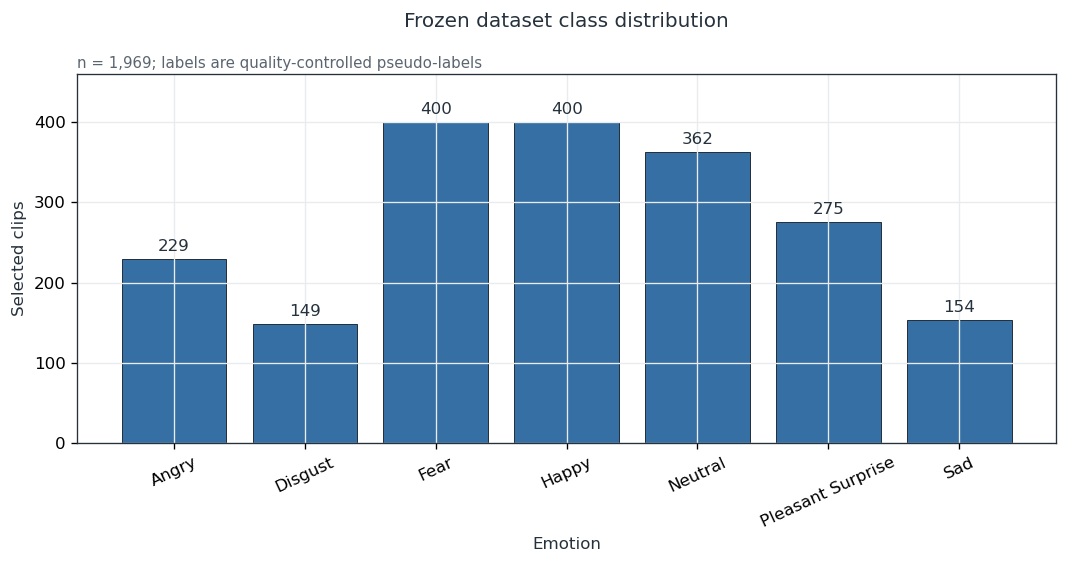

In [5]:
class_table = dataset_summary[["emotion", "samples", "share_percent", "source_groups", "transcripts"]].copy()
class_table["emotion"] = class_table["emotion"].str.replace("_", " ").str.title()
show_table(class_table, 2)

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(class_table["emotion"], class_table["samples"], color=COLORS["blue"], edgecolor=COLORS["ink"], linewidth=0.6)
ax.bar_label(bars, padding=3)
ax.set(xlabel="Emotion", ylabel="Selected clips")
ax.set_title("Frozen dataset class distribution", pad=28)
ax.set_ylim(0, max(class_table["samples"]) * 1.15)
ax.tick_params(axis="x", rotation=25)
ax.text(0, 1.015, "n = 1,969; labels are quality-controlled pseudo-labels", transform=ax.transAxes, fontsize=9, color="#5B6570")
fig.tight_layout()
plt.show()

In [6]:
split_table = pd.DataFrame([
    {"split": split.title(), "samples": len(frame), "share_percent": len(frame) / len(metadata) * 100, "source_groups": frame["source_group"].nunique()}
    for split, frame in manifests.items()
])
show_table(split_table, 2)
display(Markdown("**Terminology:** source-media/episode group-disjoint. This is not a verified speaker-independent split."))

split,samples,share_percent,source_groups
Train,1313,66.68,186
Validation,261,13.26,33
Test,395,20.06,55


**Terminology:** source-media/episode group-disjoint. This is not a verified speaker-independent split.

### Existing readiness warnings

In [7]:
show_table(pipeline_readiness)
display(Markdown("The historical readiness file is shown without reinterpretation. Later speaker analysis is exploratory and does not convert these data into verified character- or speaker-labeled data."))

check,observed,status
Auto Split ready_for_final_training,no,BLOCKER
Accepted audio mapped to cluster manifest,1969/1969,pass
Transcript coverage,100.0%,pass
Known speaker clusters,0.0%,BLOCKER
Identified characters,0.0%,BLOCKER
Cluster-selection target reached for all emotions,no,review
Planned 1–6 second duration,92.5% inside range,review


The historical readiness file is shown without reinterpretation. Later speaker analysis is exploratory and does not convert these data into verified character- or speaker-labeled data.

## Main method comparison

In [8]:
canonical_main_methods = [
    "openSMILE eGeMAPS + XGBoost", "MFCC + SVM", "MFCC + Random Forest",
    "MFCC + Gaussian Naive Bayes", "MFCC + k-NN", "MFCC + Decision Tree",
]
main_canonical = canonical_results.loc[canonical_results["method"].isin(canonical_main_methods), [
    "method", "accuracy", "macro_precision", "macro_recall", "macro_f1"
]].copy()
main_canonical["experiment_scope"] = "canonical"
main_canonical["source_artifact"] = "output/anime_only_final_results.csv"

weighted_main = weighted_results.rename(columns={
    "test_accuracy": "accuracy", "test_macro_precision": "macro_precision",
    "test_macro_recall": "macro_recall", "test_macro_f1": "macro_f1",
})[["method", "accuracy", "macro_precision", "macro_recall", "macro_f1"]].copy()
weighted_main["experiment_scope"] = "separate weighted-loss experiment"
weighted_main["source_artifact"] = "experiments/neural_class_weighted/final_results.csv"

text_main = text_char_results.rename(columns={
    "test_accuracy": "accuracy", "test_macro_precision": "macro_precision",
    "test_macro_recall": "macro_recall", "test_macro_f1": "macro_f1",
})[["method", "accuracy", "macro_precision", "macro_recall", "macro_f1"]].copy()
text_main["experiment_scope"] = "separate Japanese-text experiment"
text_main["source_artifact"] = "experiments/text_char_ngram/final_results.csv"

main_comparison = pd.concat([main_canonical, weighted_main, text_main], ignore_index=True).sort_values(
    ["macro_f1", "accuracy"], ascending=False
).reset_index(drop=True)
main_comparison.insert(0, "rank", np.arange(1, len(main_comparison) + 1))
show_table(main_comparison, 4)

rank,method,accuracy,macro_precision,macro_recall,macro_f1,experiment_scope,source_artifact
1,openSMILE eGeMAPS + XGBoost,0.7494,0.7706,0.7438,0.7517,canonical,output/anime_only_final_results.csv
2,MFCC + SVM,0.7494,0.7407,0.7564,0.7474,canonical,output/anime_only_final_results.csv
3,MFCC + Random Forest,0.7114,0.7458,0.7153,0.7234,canonical,output/anime_only_final_results.csv
4,MFCC + Gaussian Naive Bayes,0.6987,0.6961,0.6986,0.6962,canonical,output/anime_only_final_results.csv
5,MFCC + k-NN,0.6557,0.6755,0.6548,0.6501,canonical,output/anime_only_final_results.csv
6,Log-Mel CNN + weighted cross-entropy,0.5823,0.5783,0.6215,0.5762,separate weighted-loss experiment,experiments/neural_class_weighted/final_results.csv
7,MFCC + Decision Tree,0.4810,0.4831,0.4917,0.4822,canonical,output/anime_only_final_results.csv
8,Log-Mel CNN-BiLSTM + weighted cross-entropy,0.4810,0.4642,0.4818,0.4613,separate weighted-loss experiment,experiments/neural_class_weighted/final_results.csv
9,Character TF-IDF + Logistic Regression,0.2658,0.2463,0.2429,0.2439,separate Japanese-text experiment,experiments/text_char_ngram/final_results.csv


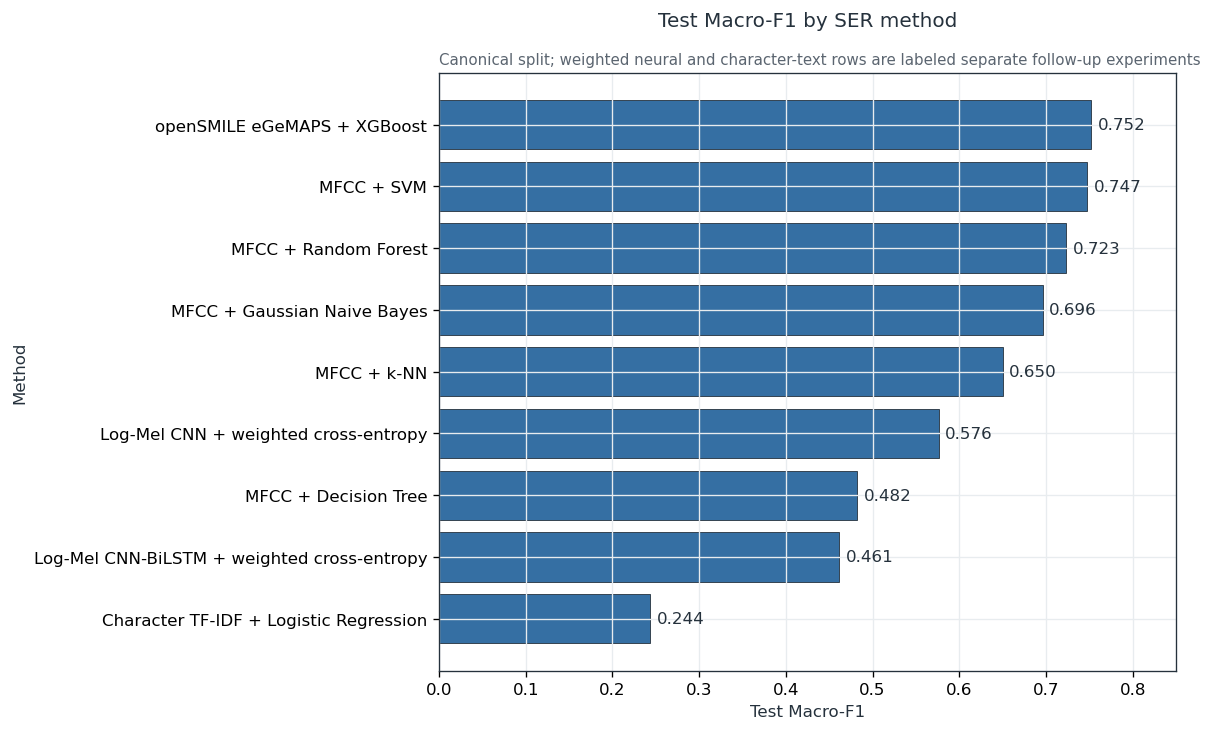

In [9]:
plot_data = main_comparison.sort_values("macro_f1")
fig, ax = plt.subplots(figsize=(10, 6.2))
bars = ax.barh(plot_data["method"], plot_data["macro_f1"], color=COLORS["blue"], edgecolor=COLORS["ink"], linewidth=0.5)
ax.bar_label(bars, labels=[f"{value:.3f}" for value in plot_data["macro_f1"]], padding=4)
ax.set(xlim=(0, 0.85), xlabel="Test Macro-F1", ylabel="Method")
ax.set_title("Test Macro-F1 by SER method", pad=28)
ax.text(0, 1.015, "Canonical split; weighted neural and character-text rows are labeled separate follow-up experiments", transform=ax.transAxes, fontsize=9, color="#5B6570")
fig.tight_layout()
plt.show()

## Original versus improved representations and loss

In [10]:
def canonical_row(method):
    return canonical_results.loc[canonical_results["method"] == method].iloc[0]

improvement_rows = []
for comparison, version, row, accuracy_field, f1_field in [
    ("Japanese text", "Original word TF-IDF", canonical_row("TF-IDF + Logistic Regression"), "accuracy", "macro_f1"),
    ("Japanese text", "Character n-gram TF-IDF", text_char_results.iloc[0], "test_accuracy", "test_macro_f1"),
    ("Log-Mel CNN", "Unweighted cross-entropy", canonical_row("Log-mel CNN"), "accuracy", "macro_f1"),
    ("Log-Mel CNN", "Weighted cross-entropy", weighted_results.loc[weighted_results["model_family"] == "cnn"].iloc[0], "test_accuracy", "test_macro_f1"),
    ("CNN-BiLSTM", "Unweighted cross-entropy", canonical_row("Log-mel CNN-BiLSTM"), "accuracy", "macro_f1"),
    ("CNN-BiLSTM", "Weighted cross-entropy", weighted_results.loc[weighted_results["model_family"] == "cnn_bilstm"].iloc[0], "test_accuracy", "test_macro_f1"),
]:
    improvement_rows.append({"comparison": comparison, "version": version, "test_accuracy": row[accuracy_field], "test_macro_f1": row[f1_field]})
improvement_comparison = pd.DataFrame(improvement_rows)
show_table(improvement_comparison, 4)
display(Markdown("The original word-level TF-IDF representation was poorly suited to unsegmented Japanese transcripts. The character n-gram result is reported as a separate baseline; the frozen fusion model still uses the original text component."))

comparison,version,test_accuracy,test_macro_f1
Japanese text,Original word TF-IDF,0.2076,0.0527
Japanese text,Character n-gram TF-IDF,0.2658,0.2439
Log-Mel CNN,Unweighted cross-entropy,0.5722,0.5487
Log-Mel CNN,Weighted cross-entropy,0.5823,0.5762
CNN-BiLSTM,Unweighted cross-entropy,0.4456,0.2974
CNN-BiLSTM,Weighted cross-entropy,0.4810,0.4613


The original word-level TF-IDF representation was poorly suited to unsegmented Japanese transcripts. The character n-gram result is reported as a separate baseline; the frozen fusion model still uses the original text component.

## Five-seed group-safe robustness

In [11]:
aggregate_view = multiseed_aggregate[[
    "model", "mean_accuracy", "std_accuracy", "mean_macro_f1", "std_macro_f1", "min_macro_f1", "max_macro_f1"
]].copy()
show_table(aggregate_view, 4)
show_table(multiseed_results[["seed", "model", "accuracy", "macro_precision", "macro_recall", "macro_f1"]], 4)

model,mean_accuracy,std_accuracy,mean_macro_f1,std_macro_f1,min_macro_f1,max_macro_f1
MFCC + SVM,0.7439,0.0174,0.7511,0.0143,0.7291,0.7643
openSMILE eGeMAPS + XGBoost,0.7517,0.0065,0.7592,0.0073,0.7517,0.7695


seed,model,accuracy,macro_precision,macro_recall,macro_f1
42,MFCC + SVM,0.7494,0.7407,0.7564,0.7474
123,MFCC + SVM,0.7506,0.7619,0.7667,0.7632
2026,MFCC + SVM,0.7136,0.7280,0.7368,0.7291
3407,MFCC + SVM,0.7579,0.7640,0.7695,0.7643
7777,MFCC + SVM,0.7481,0.7608,0.7494,0.7515
42,openSMILE eGeMAPS + XGBoost,0.7494,0.7706,0.7438,0.7517
123,openSMILE eGeMAPS + XGBoost,0.7456,0.7660,0.7431,0.7525
2026,openSMILE eGeMAPS + XGBoost,0.7468,0.7706,0.7591,0.7615
3407,openSMILE eGeMAPS + XGBoost,0.7555,0.7683,0.7553,0.7608
7777,openSMILE eGeMAPS + XGBoost,0.7610,0.7882,0.7635,0.7695


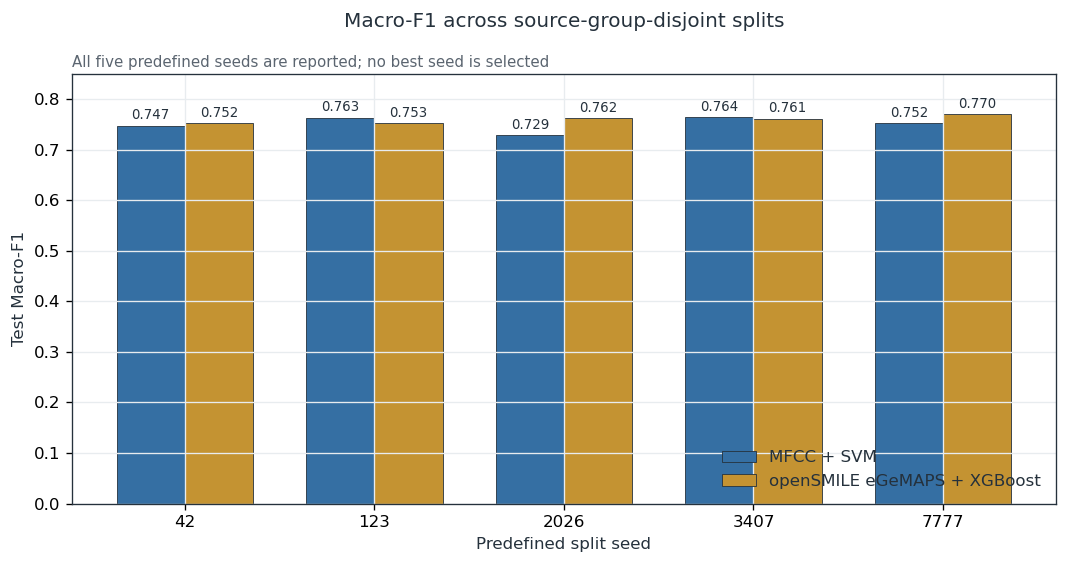

In [12]:
seed_pivot = multiseed_results.pivot(index="seed", columns="model", values="macro_f1")
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(seed_pivot.index))
width = 0.36
for offset, (model, color) in zip([-width/2, width/2], zip(seed_pivot.columns, [COLORS["blue"], COLORS["gold"]])):
    bars = ax.bar(x + offset, seed_pivot[model], width, label=model, color=color, edgecolor=COLORS["ink"], linewidth=0.5)
    ax.bar_label(bars, labels=[f"{value:.3f}" for value in seed_pivot[model]], padding=2, fontsize=8)
ax.set(xticks=x, xticklabels=seed_pivot.index.astype(str), ylim=(0, 0.85), xlabel="Predefined split seed", ylabel="Test Macro-F1")
ax.set_title("Macro-F1 across source-group-disjoint splits", pad=28)
ax.legend(frameon=False, loc="lower right")
ax.text(0, 1.015, "All five predefined seeds are reported; no best seed is selected", transform=ax.transAxes, fontsize=9, color="#5B6570")
fig.tight_layout()
plt.show()

## Best canonical model: class-wise performance

emotion,precision,recall,f1,support
fear,0.7895,0.9375,0.8571,80
sad,0.8621,0.8065,0.8333,31
disgust,0.8261,0.7600,0.7917,25
angry,0.8000,0.7111,0.7529,45
happy,0.6634,0.8171,0.7322,82
neutral,0.7419,0.6667,0.7023,69
pleasant_surprise,0.7111,0.5079,0.5926,63


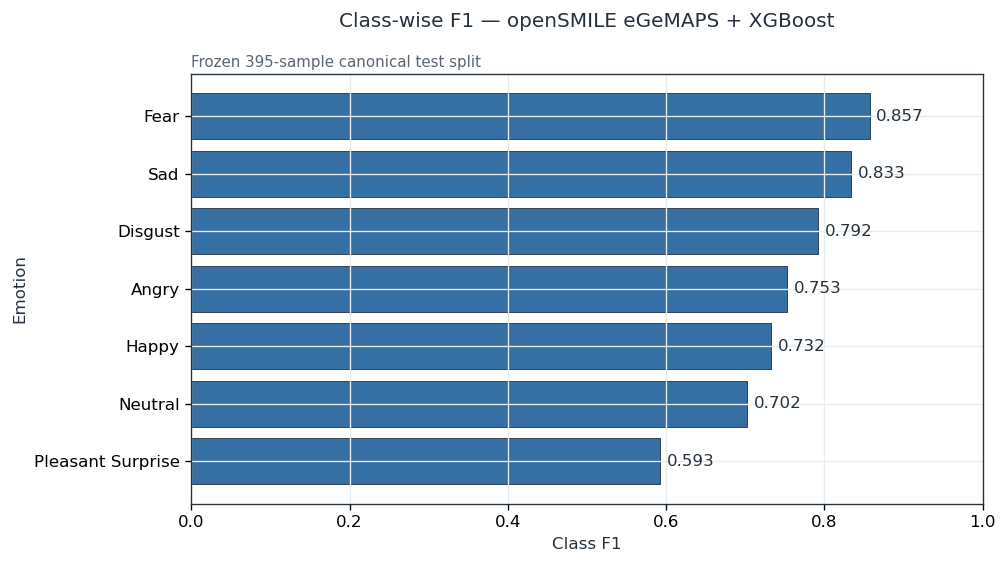

In [13]:
best_classwise = canonical_classwise.loc[
    canonical_classwise["method"] == best["method"], ["emotion", "precision", "recall", "f1", "support"]
].copy().sort_values("f1", ascending=False)
show_table(best_classwise, 4)

plot_classwise = best_classwise.sort_values("f1")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(plot_classwise["emotion"].str.replace("_", " ").str.title(), plot_classwise["f1"], color=COLORS["blue"], edgecolor=COLORS["ink"], linewidth=0.5)
ax.bar_label(bars, labels=[f"{value:.3f}" for value in plot_classwise["f1"]], padding=4)
ax.set(xlim=(0, 1), xlabel="Class F1", ylabel="Emotion")
ax.set_title(f"Class-wise F1 — {best['method']}", pad=28)
ax.text(0, 1.015, "Frozen 395-sample canonical test split", transform=ax.transAxes, fontsize=9, color="#5B6570")
fig.tight_layout()
plt.show()

## Duration-policy analysis

count,minimum_seconds,maximum_seconds,mean_seconds,median_seconds,standard_deviation_seconds,standard_deviation_definition,percentile_25_seconds,percentile_75_seconds
1969,0.650,5.340,2.022,1.920,0.796,population_ddof_0,1.425,2.435


duration_policy_category,sample_count,percentage_of_dataset
below_1.00_second,148,7.517
within_1.00_to_6.00_seconds,1821,92.483
above_6.00_seconds,0,0.000


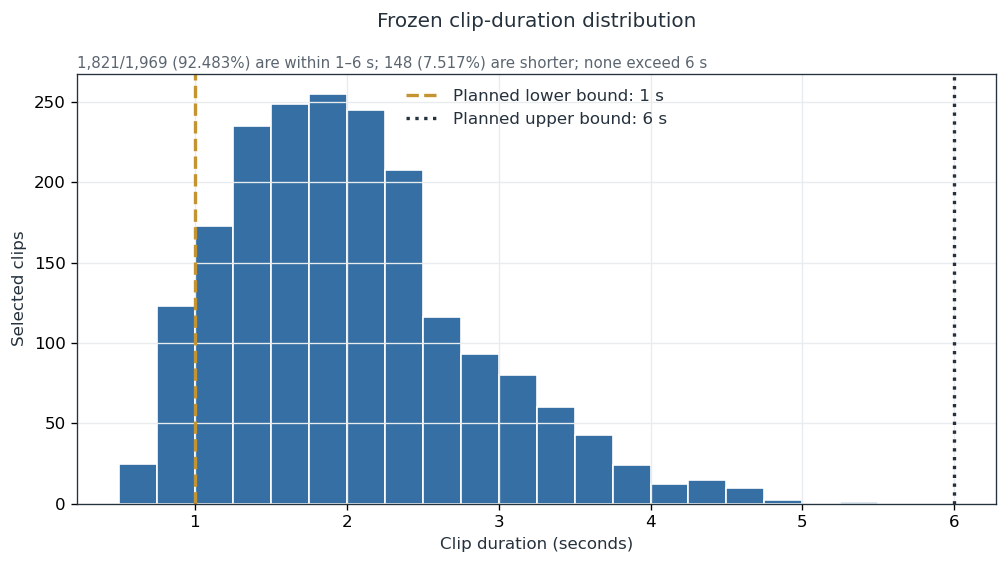

The 1–6 s range was an approximate planning guideline. The upstream implementation intentionally permitted clips from 0.65 s when they passed the remaining Japanese-dialogue, audio-quality, and clean-selection criteria.

In [14]:
show_table(duration_summary, 3)
show_table(duration_policy, 3)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hist(duration_distribution["duration_sec"], bins=np.arange(0.5, 5.6, 0.25), color=COLORS["blue"], edgecolor="white")
ax.axvline(1.0, color=COLORS["gold"], linestyle="--", linewidth=2, label="Planned lower bound: 1 s")
ax.axvline(6.0, color=COLORS["ink"], linestyle=":", linewidth=2, label="Planned upper bound: 6 s")
ax.set(xlabel="Clip duration (seconds)", ylabel="Selected clips")
ax.set_title("Frozen clip-duration distribution", pad=28)
ax.legend(frameon=False)
ax.text(0, 1.015, "1,821/1,969 (92.483%) are within 1–6 s; 148 (7.517%) are shorter; none exceed 6 s", transform=ax.transAxes, fontsize=9, color="#5B6570")
fig.tight_layout()
plt.show()

display(Markdown("The 1–6 s range was an approximate planning guideline. The upstream implementation intentionally permitted clips from 0.65 s when they passed the remaining Japanese-dialogue, audio-quality, and clean-selection criteria."))

## Speaker-analysis limitation

In [15]:
cluster_count = int(speaker_config["estimated_cluster_count"])
singleton_count = int((pd.read_csv(SPEAKER_ANALYSIS / "speaker_cluster_summary.csv")["clip_count"] == 1).sum())
cross = speaker_overlap.loc[speaker_overlap["overlap_category"] == "any_cross_split"].iloc[0]
display(Markdown(f'''
- ECAPA clustering is an **exploratory voice-similarity analysis**, not character recognition or verified identity.
- It produced **{cluster_count:,} estimated similarity groups**, including **{singleton_count:,} singletons**. Do not report {cluster_count:,} as the number of real speakers.
- **{int(cross['cluster_count'])} groups / {int(cross['unique_clip_count'])} clips ({cross['clip_percentage_of_all']:.3f}%)** were estimated to cross at least two splits.
- Domain mismatch, expressive acting, short clips, music/effects, false splits, and false merges limit reliability.
- Continue to call the evaluation **source-media/episode group-disjoint**; do not claim speaker independence.
'''))


- ECAPA clustering is an **exploratory voice-similarity analysis**, not character recognition or verified identity.
- It produced **1,526 estimated similarity groups**, including **1,305 singletons**. Do not report 1,526 as the number of real speakers.
- **92 groups / 353 clips (17.928%)** were estimated to cross at least two splits.
- Domain mismatch, expressive acting, short clips, music/effects, false splits, and false merges limit reliability.
- Continue to call the evaluation **source-media/episode group-disjoint**; do not claim speaker independence.


## Label-methodology statement

The seven emotion labels are **quality-controlled pseudo-labels** targeting the emotion perceived from the character’s vocal delivery. Acoustic evidence—including pitch, intensity, rhythm, speaking rate, pauses, breathiness, voice quality, intonation, and anime-style delivery—is primary. Japanese transcript meaning is supporting evidence and may express a character’s emotional situation indirectly; lexical content is not treated as proof that the voice itself has the same emotion. Visual context and full-scene emotion are outside the classifier target.

These labels must not be described as independently verified human ground truth unless the separate human audit is completed and analyzed.

## Final consistency checklist

In [16]:
seed42 = multiseed_results.loc[multiseed_results["seed"] == 42].set_index("model")
canonical_index = canonical_results.set_index("method")
checks = [
    ("All required saved artifacts exist", not missing_artifacts, "18/18 sources loaded"),
    ("Frozen dataset has exactly 1,969 rows", len(metadata) == 1969, len(metadata)),
    ("Canonical split membership is 1,313/261/395", split_sizes == expected_split_sizes, split_sizes),
    ("Seven emotion counts sum to 1,969", dataset_summary["samples"].sum() == 1969, int(dataset_summary["samples"].sum())),
    ("No duplicate paths", metadata["file_path"].nunique() == 1969, metadata["file_path"].nunique()),
    ("No duplicate SHA-256 values", metadata["sha256"].nunique() == 1969, metadata["sha256"].nunique()),
    ("Transcript coverage is 100%", metadata["transcript"].fillna("").str.strip().ne("").all(), f"{metadata['transcript'].fillna('').str.strip().ne('').mean():.1%}"),
    ("Zero source-group overlap", all(len(source_groups[a] & source_groups[b]) == 0 for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]), 0),
    ("Seed 42 reproduces canonical openSMILE Macro-F1", np.isclose(seed42.loc["openSMILE eGeMAPS + XGBoost", "macro_f1"], canonical_index.loc["openSMILE eGeMAPS + XGBoost", "macro_f1"], atol=1e-12), seed42.loc["openSMILE eGeMAPS + XGBoost", "macro_f1"]),
    ("Seed 42 reproduces canonical SVM Macro-F1", np.isclose(seed42.loc["MFCC + SVM", "macro_f1"], canonical_index.loc["MFCC + SVM", "macro_f1"], atol=1e-12), seed42.loc["MFCC + SVM", "macro_f1"]),
    ("Duration categories sum to 1,969", duration_policy["sample_count"].sum() == 1969, int(duration_policy["sample_count"].sum())),
    ("Speaker metadata represents 1,969 clips", len(speaker_metadata) == 1969, len(speaker_metadata)),
    ("Main table rows trace to approved saved sources", main_comparison["source_artifact"].notna().all(), len(main_comparison)),
    ("Notebook performs no training or test evaluation", True, "read/aggregate/plot only"),
]
consistency_checklist = pd.DataFrame([
    {"check": name, "status": "PASS" if passed else "FAIL", "observed": observed}
    for name, passed, observed in checks
])
show_table(consistency_checklist)
assert consistency_checklist["status"].eq("PASS").all()
display(Markdown("**Consistency status: PASS. Every displayed quantitative result comes from an existing frozen or versioned artifact.**"))

check,status,observed
All required saved artifacts exist,PASS,18/18 sources loaded
"Frozen dataset has exactly 1,969 rows",PASS,1969
"Canonical split membership is 1,313/261/395",PASS,"{'train': 1313, 'validation': 261, 'test': 395}"
"Seven emotion counts sum to 1,969",PASS,1969
No duplicate paths,PASS,1969
No duplicate SHA-256 values,PASS,1969
Transcript coverage is 100%,PASS,100.0%
Zero source-group overlap,PASS,0
Seed 42 reproduces canonical openSMILE Macro-F1,PASS,0.7517
Seed 42 reproduces canonical SVM Macro-F1,PASS,0.7474


**Consistency status: PASS. Every displayed quantitative result comes from an existing frozen or versioned artifact.**

## Takeaways

1. The two strongest canonical methods are openSMILE eGeMAPS + XGBoost and MFCC + SVM, both near 0.75 test Macro-F1.
2. Five-seed analysis supports strong split stability for openSMILE and modestly greater variability for MFCC + SVM.
3. Weighted loss materially improved the separately evaluated CNN-BiLSTM, including previously zero-F1 classes, but it remains a follow-up robustness experiment.
4. Character n-gram TF-IDF is more suitable than the original word representation for unsegmented Japanese, although text-only performance remains far below the acoustic leaders.
5. Duration policy is a documented implementation refinement: 92.483% of clips meet the planned 1–6 s interval, and the remainder are shorter accepted utterances.
6. Speaker similarity results remain exploratory. The canonical study must not be described as speaker-independent.
7. The existing pipeline-readiness warning and pseudo-label limitation should remain visible in thesis reporting.